In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [37]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [38]:
df=pd.read_csv('/content/drive/My Drive/datasets/trainn.csv')


X=df.drop('prognosis', axis=1)
y=df['prognosis']


le=LabelEncoder()
y_encoded = le.fit_transform(y)

In [30]:
X_train, X_test, y_train, y_test=train_test_split(
    X,y_encoded,test_size=0.2,random_state=42,stratify=y_encoded
)

In [31]:

rf=RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train,y_train)

rf_pred=rf.predict(X_test)
rf_accuracy=accuracy_score(y_test, rf_pred)
rf_cv=cross_val_score(rf, X, y_encoded,cv=5).mean()

print("Test Accuracy: ",rf_accuracy)
print("Cross-Validation Accuracy: ",rf_cv)

Test Accuracy:  0.9607843137254902
Cross-Validation Accuracy:  0.928392156862745


✅ Accuracy: 0.9608

📊 Classification Report:
                       precision    recall  f1-score
Chikungunya             0.833333  1.000000  0.909091
Dengue                  1.000000  0.750000  0.857143
Japanese encephalitis   1.000000  1.000000  1.000000
Lyme disease            1.000000  1.000000  1.000000
Malaria                 1.000000  1.000000  1.000000
Plague                  1.000000  1.000000  1.000000
Rift Valley fever       1.000000  0.750000  0.857143
Tungiasis               1.000000  1.000000  1.000000
West Nile fever         0.833333  1.000000  0.909091
Yellow Fever            1.000000  1.000000  1.000000
Zika                    1.000000  1.000000  1.000000
accuracy                0.960784  0.960784  0.960784
macro avg               0.969697  0.954545  0.957497
weighted avg            0.967320  0.960784  0.959766


<Figure size 1200x600 with 0 Axes>

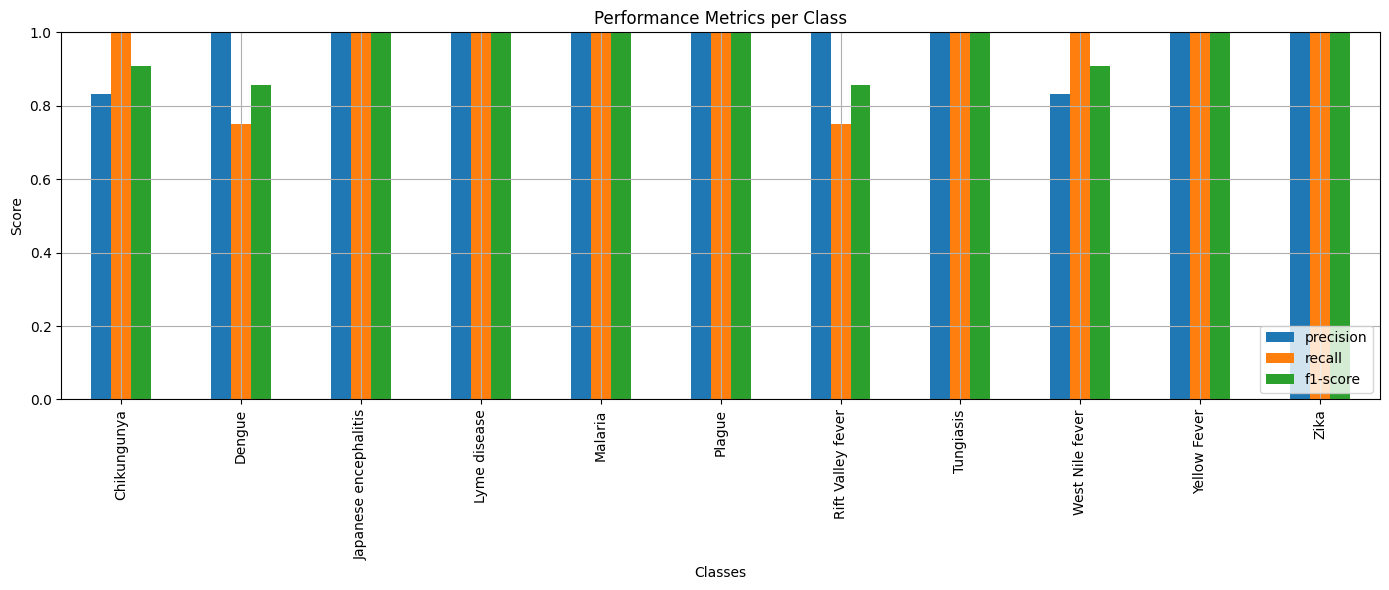

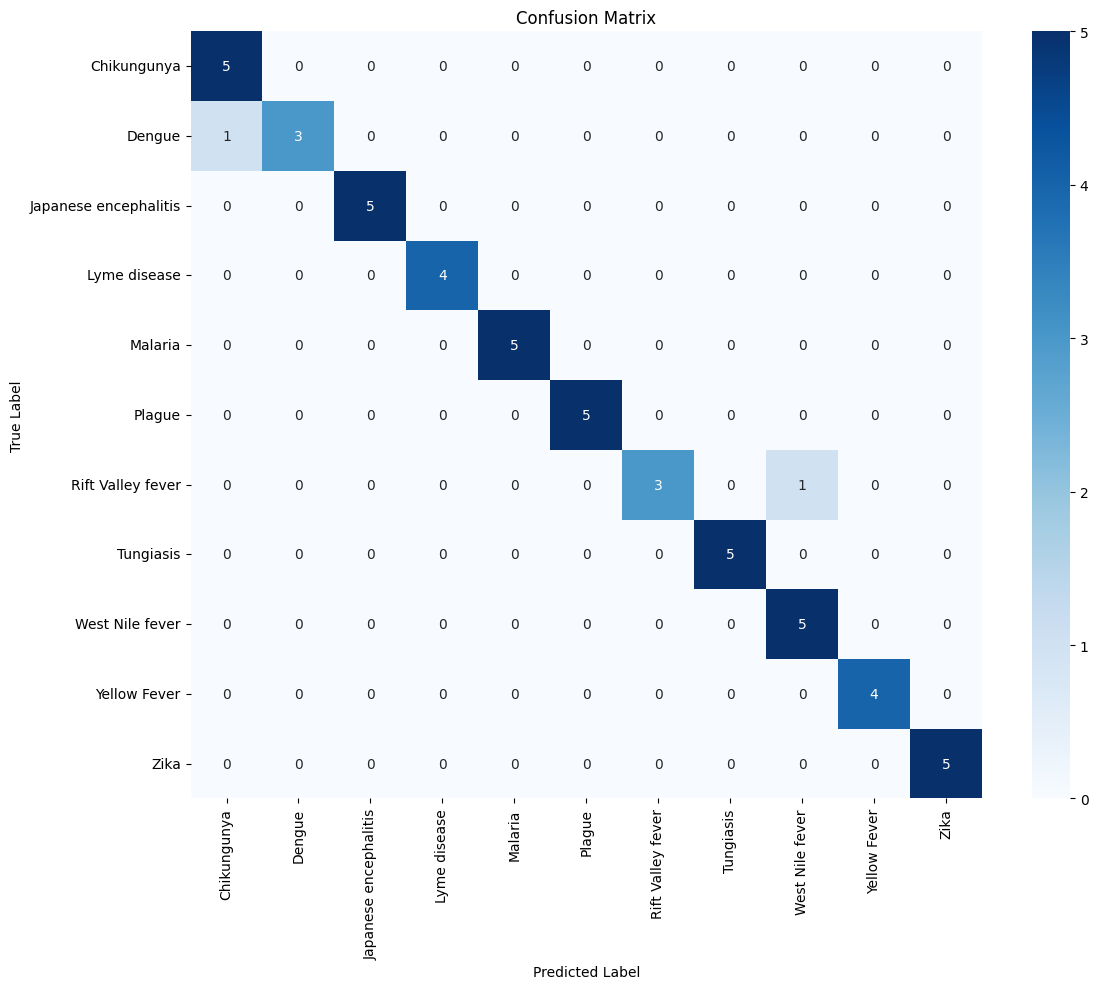

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

# Make predictions
y_pred = rf.predict(X_test)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"✅ Accuracy: {acc:.4f}")

# Classification Report
report = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Display classification metrics table
print("\n📊 Classification Report:")
print(report_df[['precision', 'recall', 'f1-score']])

# 📌 Plot classification report as bar charts
plt.figure(figsize=(12, 6))
report_df[:-3][['precision', 'recall', 'f1-score']].plot(kind='bar', figsize=(14,6))
plt.title('Performance Metrics per Class')
plt.xlabel('Classes')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=90)
plt.grid(True)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 🔍 Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


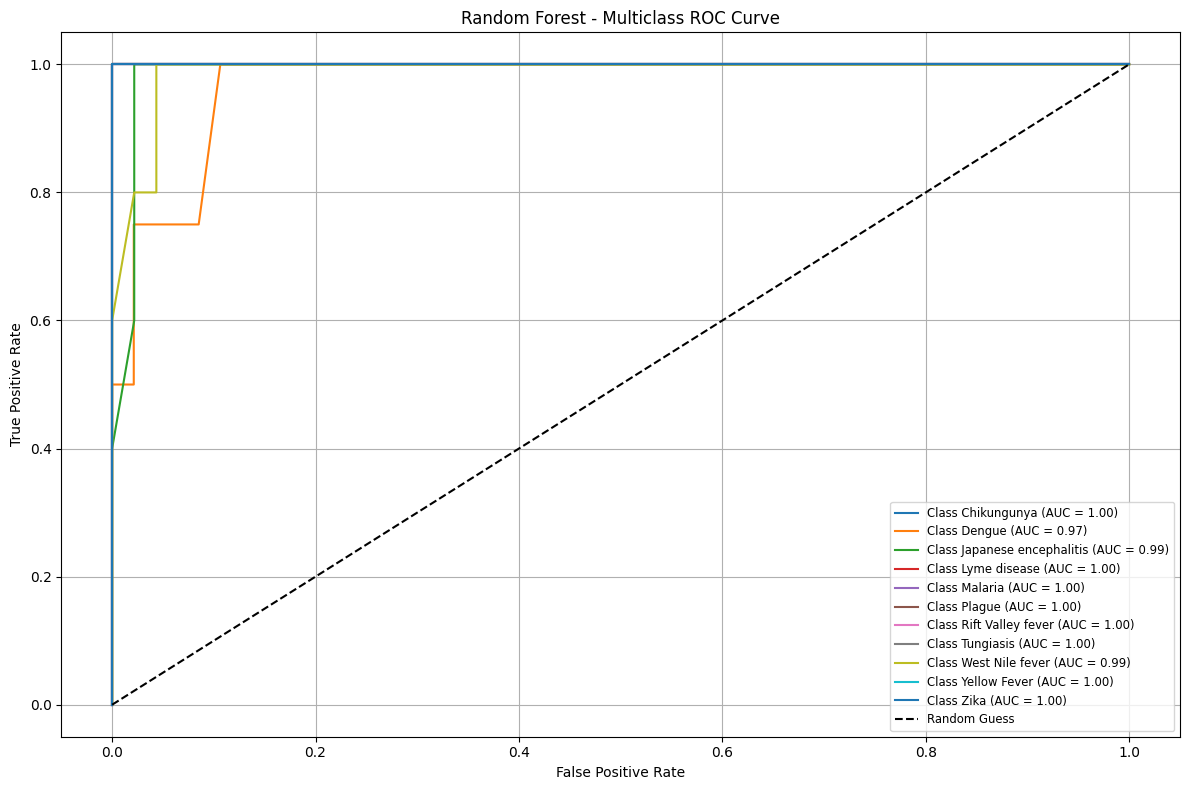

In [33]:
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Binarize the labels
y_test_bin = label_binarize(y_test, classes=np.unique(y_encoded))
y_train_bin = label_binarize(y_train, classes=np.unique(y_encoded))
n_classes = y_test_bin.shape[1]

# One-vs-Rest wrapper for Random Forest
rf_ovr = OneVsRestClassifier(RandomForestClassifier(n_estimators=100, random_state=42))
rf_ovr.fit(X_train, y_train_bin)

# Predict probabilities
y_score = rf_ovr.predict_proba(X_test)

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(12, 8))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f"Class {le.classes_[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.title("Random Forest - Multiclass ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize='small')
plt.grid(True)
plt.tight_layout()
plt.show()


In [22]:
!pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 7.6 MB/s eta 0:00:00


In [35]:
from catboost import CatBoostClassifier

# Initialize and train CatBoost
cat = CatBoostClassifier(verbose=0, random_state=42)
cat.fit(X_train, y_train)

# Predict
y_pred_cat = cat.predict(X_test)

# Accuracy
print(f"CatBoost Accuracy: {accuracy_score(y_test, y_pred_cat):.4f}")


CatBoost Accuracy: 0.9412


✅ Accuracy: 0.9412

📊 Classification Report:
                       precision    recall  f1-score
Chikungunya             0.833333  1.000000  0.909091
Dengue                  1.000000  0.750000  0.857143
Japanese encephalitis   1.000000  1.000000  1.000000
Lyme disease            1.000000  1.000000  1.000000
Malaria                 1.000000  1.000000  1.000000
Plague                  1.000000  1.000000  1.000000
Rift Valley fever       1.000000  0.500000  0.666667
Tungiasis               1.000000  1.000000  1.000000
West Nile fever         0.714286  1.000000  0.833333
Yellow Fever            1.000000  1.000000  1.000000
Zika                    1.000000  1.000000  1.000000
accuracy                0.941176  0.941176  0.941176
macro avg               0.958874  0.931818  0.933294
weighted avg            0.955649  0.941176  0.937399


<Figure size 1200x600 with 0 Axes>

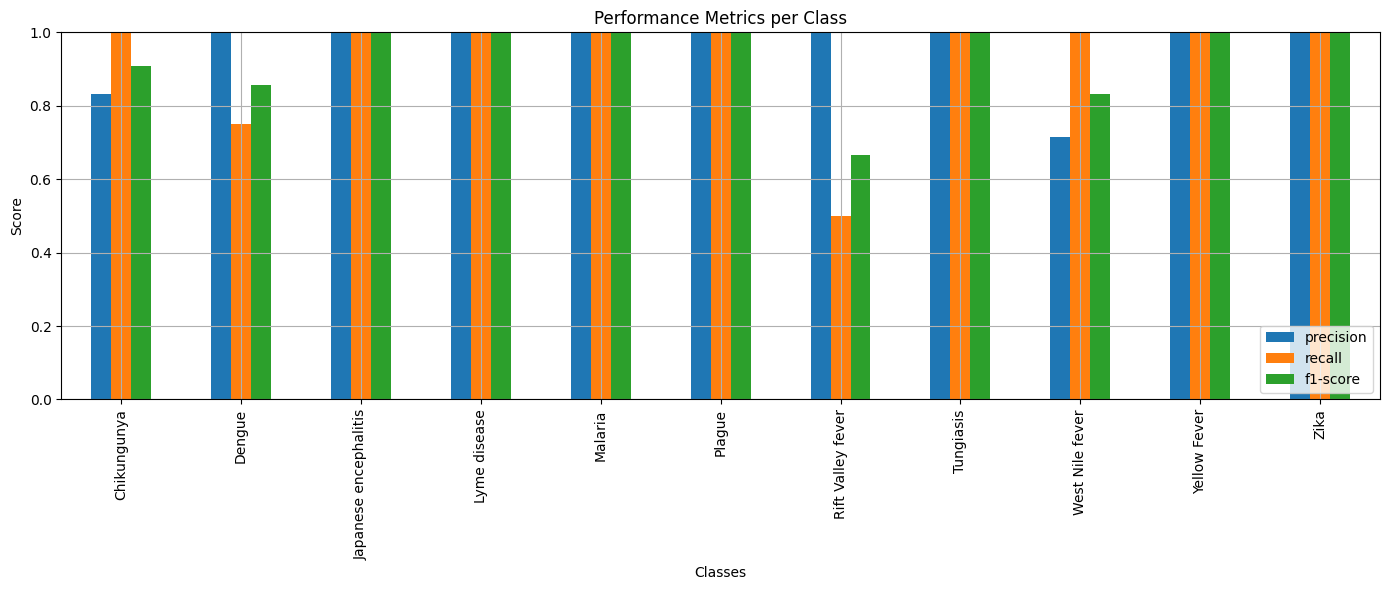

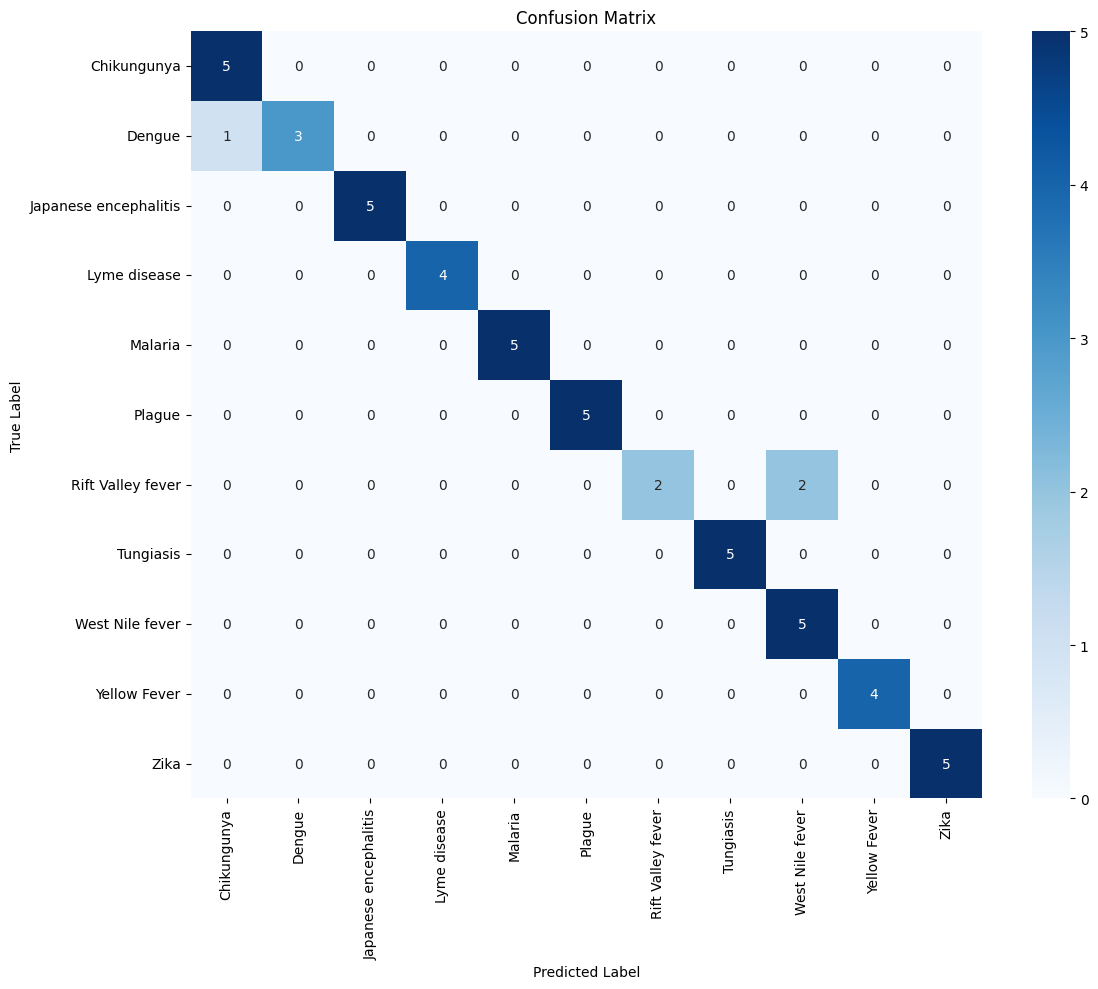

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

# Make predictions
y_pred = cat.predict(X_test)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"✅ Accuracy: {acc:.4f}")

# Classification Report
report = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Display classification metrics table
print("\n📊 Classification Report:")
print(report_df[['precision', 'recall', 'f1-score']])

# 📌 Plot classification report as bar charts
plt.figure(figsize=(12, 6))
report_df[:-3][['precision', 'recall', 'f1-score']].plot(kind='bar', figsize=(14,6))
plt.title('Performance Metrics per Class')
plt.xlabel('Classes')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=90)
plt.grid(True)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 🔍 Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


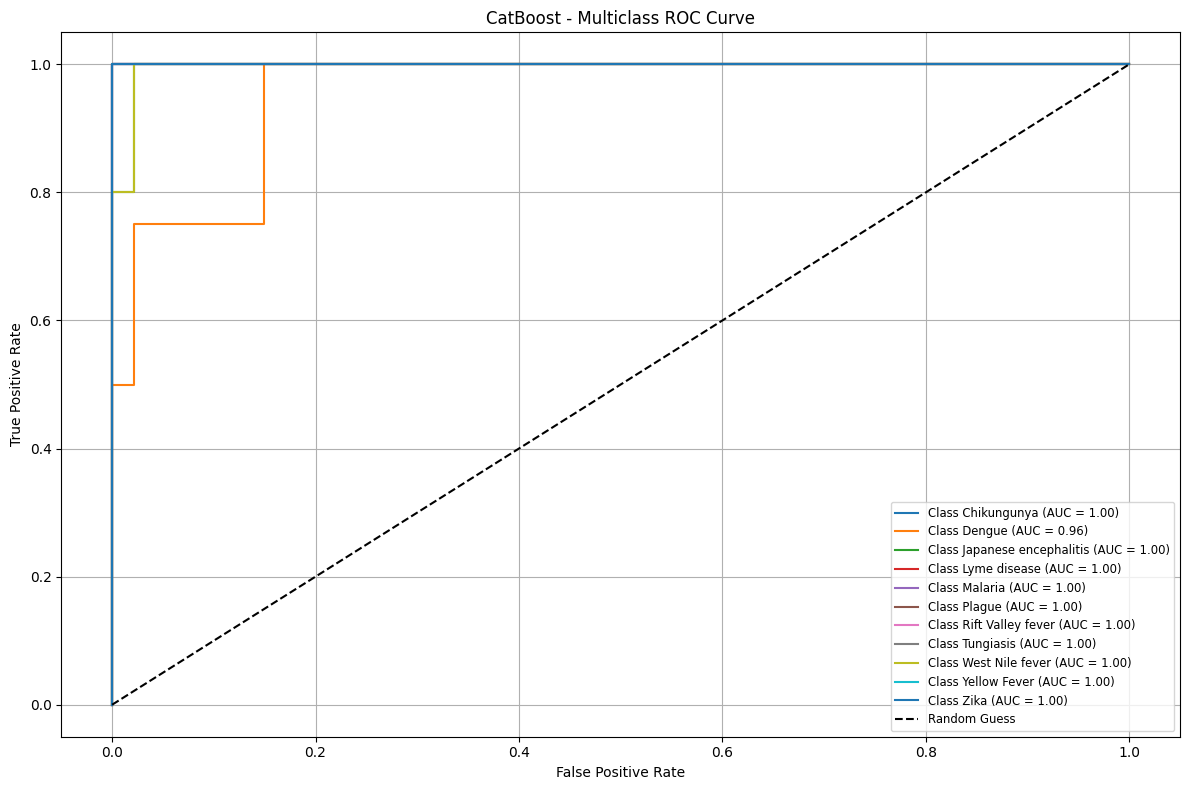

In [39]:
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np
from catboost import CatBoostClassifier

# Binarize the labels
y_train_bin = label_binarize(y_train, classes=np.unique(y_encoded))
y_test_bin = label_binarize(y_test, classes=np.unique(y_encoded))
n_classes = y_test_bin.shape[1]

# One-vs-Rest CatBoost
cat_ovr = OneVsRestClassifier(CatBoostClassifier(verbose=0, random_state=42))
cat_ovr.fit(X_train, y_train_bin)

# Predict probabilities
y_score = cat_ovr.predict_proba(X_test)

# Compute ROC and AUC per class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC curves
plt.figure(figsize=(12, 8))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], label=f"Class {le.classes_[i]} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.title("CatBoost - Multiclass ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize='small')
plt.grid(True)
plt.tight_layout()
plt.show()


In [7]:
from sklearn.svm import SVC

# Initialize and train SVM
svm = SVC(kernel='linear', probability=True, random_state=42)
svm.fit(X_train, y_train)

# Predict
y_pred = svm.predict(X_test)

# Accuracy
from sklearn.metrics import accuracy_score
print(f"SVM Accuracy: {accuracy_score(y_test, y_pred):.4f}")

SVM Accuracy: 0.8627


✅ Accuracy: 0.8627

📊 Classification Report:
                       precision    recall  f1-score
Chikungunya             0.833333  1.000000  0.909091
Dengue                  0.600000  0.750000  0.666667
Japanese encephalitis   0.600000  0.600000  0.600000
Lyme disease            1.000000  1.000000  1.000000
Malaria                 1.000000  0.800000  0.888889
Plague                  1.000000  1.000000  1.000000
Rift Valley fever       1.000000  0.750000  0.857143
Tungiasis               1.000000  1.000000  1.000000
West Nile fever         0.750000  0.600000  0.666667
Yellow Fever            1.000000  1.000000  1.000000
Zika                    0.833333  1.000000  0.909091
accuracy                0.862745  0.862745  0.862745
macro avg               0.874242  0.863636  0.863413
weighted avg            0.872222  0.862745  0.862038


<Figure size 1200x600 with 0 Axes>

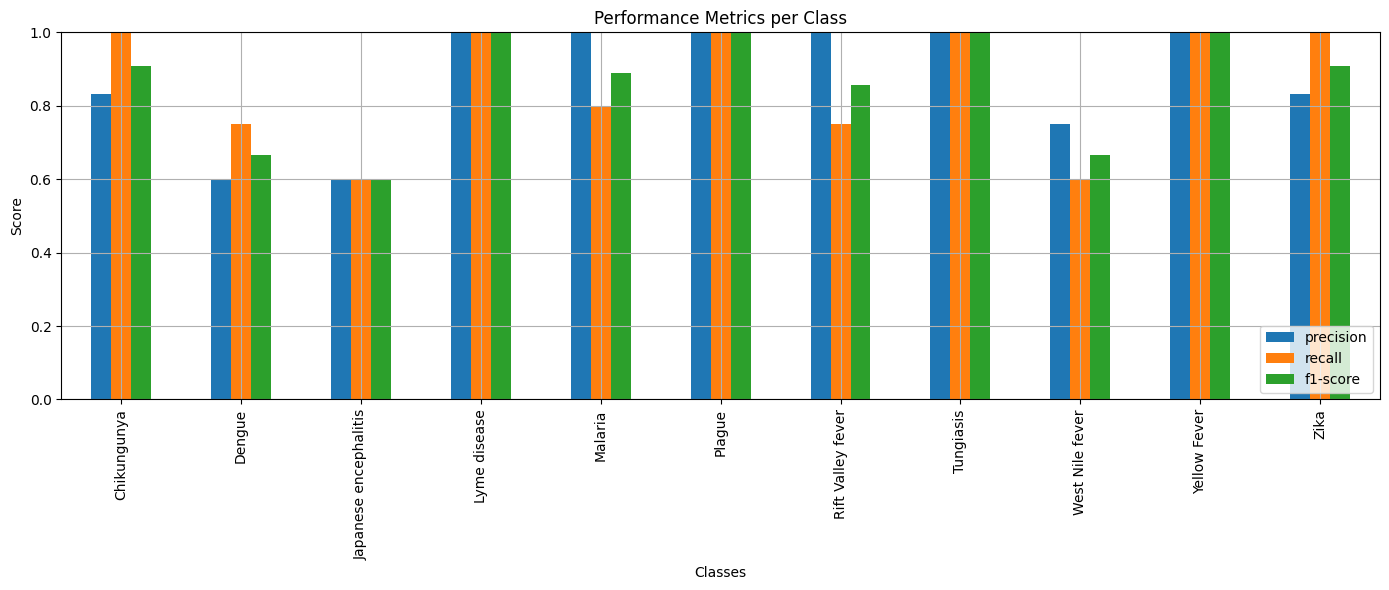

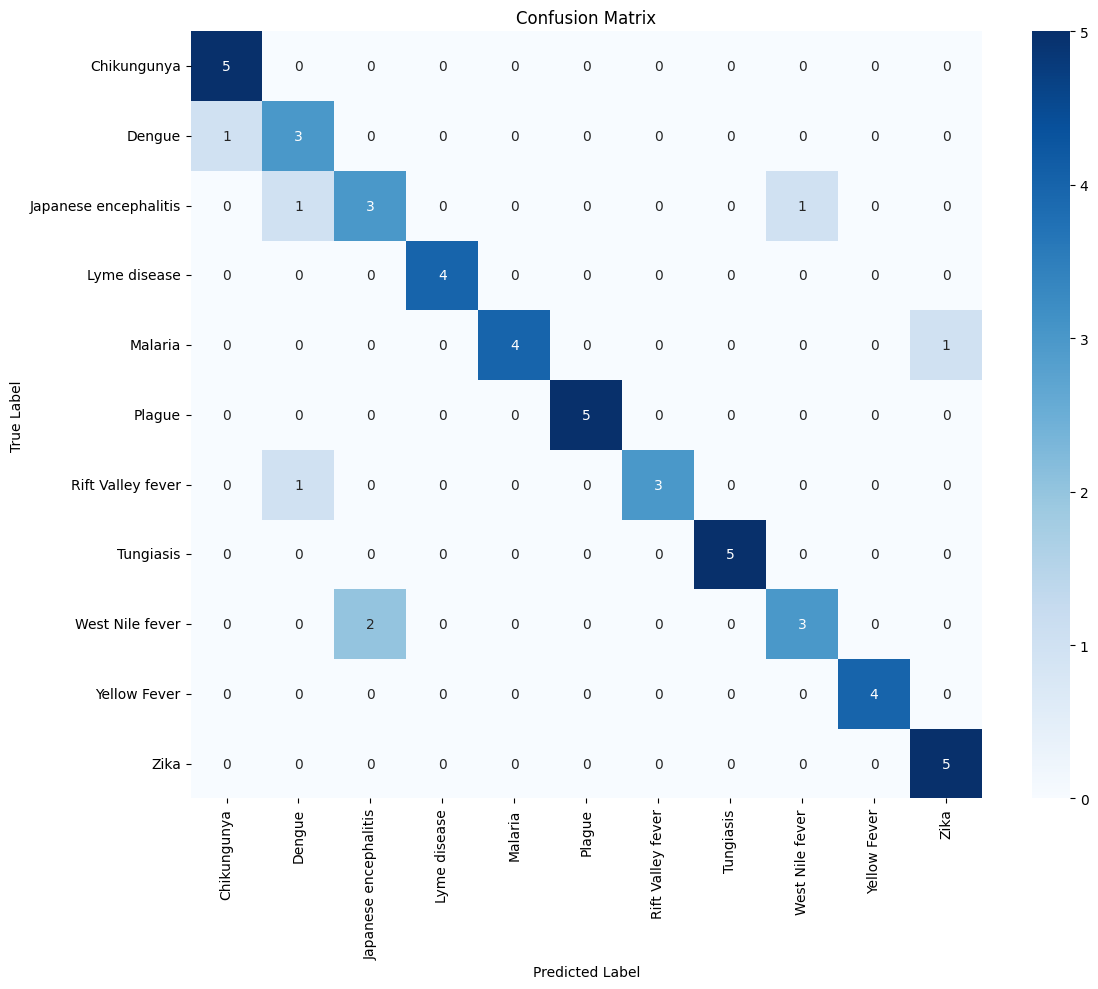

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

# Make predictions
y_pred = svm.predict(X_test)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"✅ Accuracy: {acc:.4f}")

# Classification Report
report = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Display classification metrics table
print("\n📊 Classification Report:")
print(report_df[['precision', 'recall', 'f1-score']])

# 📌 Plot classification report as bar charts
plt.figure(figsize=(12, 6))
report_df[:-3][['precision', 'recall', 'f1-score']].plot(kind='bar', figsize=(14,6))
plt.title('Performance Metrics per Class')
plt.xlabel('Classes')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=90)
plt.grid(True)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 🔍 Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Initialize and train KNN
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Predict
y_pred_knn = knn.predict(X_test)

# Accuracy
print(f"KNN Accuracy: {accuracy_score(y_test, y_pred_knn):.4f}")


KNN Accuracy: 0.7451


✅ Accuracy: 0.7451

📊 Classification Report:
                       precision    recall  f1-score
Chikungunya             0.500000  1.000000  0.666667
Dengue                  0.500000  0.250000  0.333333
Japanese encephalitis   0.750000  0.600000  0.666667
Lyme disease            1.000000  1.000000  1.000000
Malaria                 1.000000  0.800000  0.888889
Plague                  1.000000  1.000000  1.000000
Rift Valley fever       1.000000  0.500000  0.666667
Tungiasis               1.000000  1.000000  1.000000
West Nile fever         1.000000  0.600000  0.750000
Yellow Fever            0.375000  0.750000  0.500000
Zika                    0.750000  0.600000  0.666667
accuracy                0.745098  0.745098  0.745098
macro avg               0.806818  0.736364  0.739899
weighted avg            0.813725  0.745098  0.748911


<Figure size 1200x600 with 0 Axes>

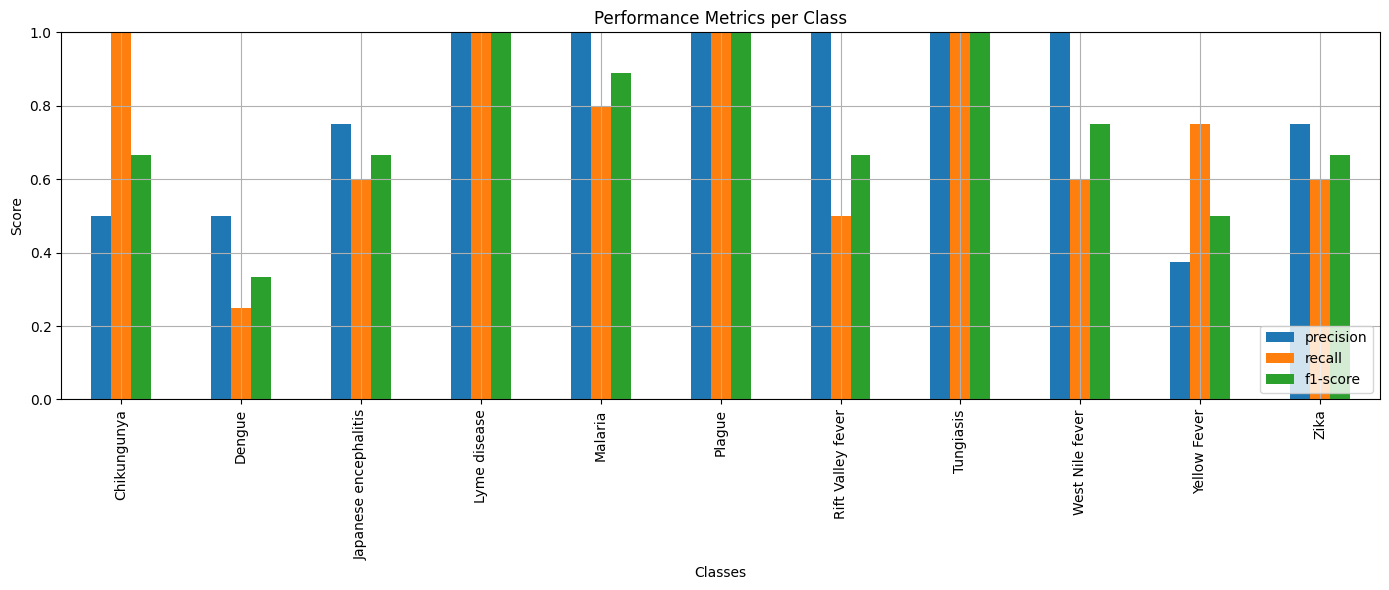

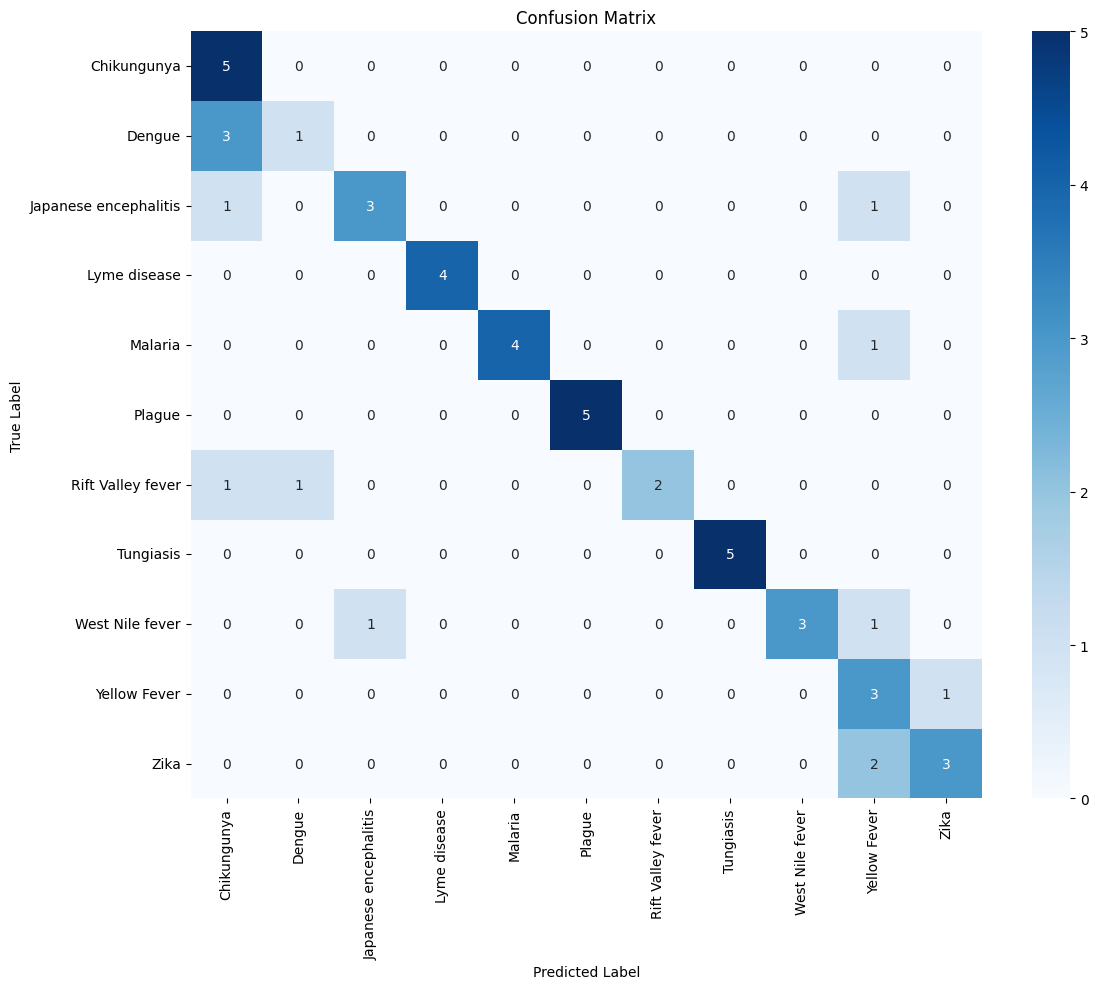

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

# Make predictions
y_pred = knn.predict(X_test)

# Accuracy
acc = accuracy_score(y_test, y_pred)
print(f"✅ Accuracy: {acc:.4f}")

# Classification Report
report = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Display classification metrics table
print("\n📊 Classification Report:")
print(report_df[['precision', 'recall', 'f1-score']])

# 📌 Plot classification report as bar charts
plt.figure(figsize=(12, 6))
report_df[:-3][['precision', 'recall', 'f1-score']].plot(kind='bar', figsize=(14,6))
plt.title('Performance Metrics per Class')
plt.xlabel('Classes')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=90)
plt.grid(True)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# 🔍 Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
